<a href="https://colab.research.google.com/github/aiaanad/metopt26/blob/main/lab2/%D0%A2%D0%B5%D0%BC%D0%B0_2_%D0%94%D0%B0%D0%BD%D0%B8%D0%BB%D0%BE%D0%B2%D0%B0_%D0%90%D0%B9%D0%B0%D0%B0%D0%BD%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
input = {
    "function": "10 + x**2 - 10 * cos(2*pi*x)",
    "a": 0.75,
    "b": 2.75,
    "eps": 1e-3,
}

In [ ]:
input = {
    "function": "x + sin(3.14159*x)",
    "a": 0.75,
    "b": 2.75,
    "eps": 1e-3,
}

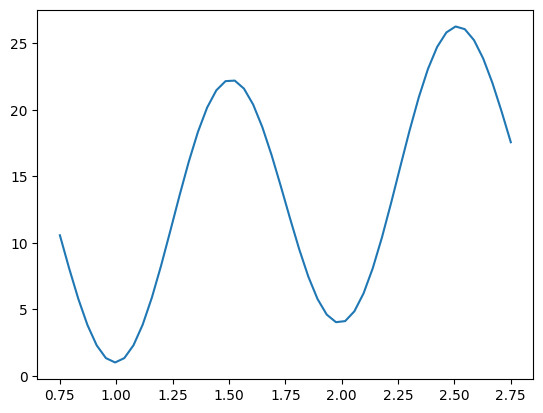

Вычисленная константа Липшица: 68.00598208647202
РЕЗУЛЬТАТЫ РАСЧЕТОВ
Минимум (X, Y): [np.float64(0.9950581889776134), 0.9949610222829364]
Число итераций: 87
Затраченное время: 0.0792 сек


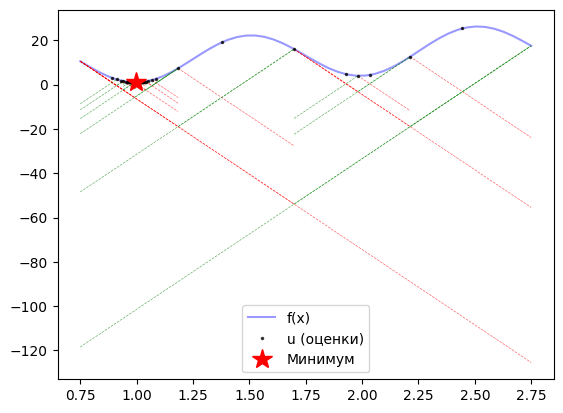

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
import time
import heapq
from typing import Optional

from functools import wraps


def gather_stats(func):
    @wraps(func)
    def wrapper(*args, **kwargs):
        is_top_level = False
        if 'mins' not in kwargs or kwargs['mins'] is None:
            kwargs['mins'] = []
            is_top_level = True
        if 'stats' not in kwargs or kwargs['stats'] is None:
            kwargs['stats'] = {'iterations': 0}

        start_time = time.perf_counter() if is_top_level else 0

        func(*args, **kwargs)

        if is_top_level:
            total_time = time.perf_counter() - start_time
            mins = kwargs['mins']
            stats = kwargs['stats']

            local_min = min(mins, key=lambda x: x[1]) if mins else None

            print("="*40)
            print("РЕЗУЛЬТАТЫ РАСЧЕТОВ")
            print(f"Минимум (X, Y): {local_min}")
            print(f"Число итераций: {stats['iterations']}")
            print(f"Затраченное время: {total_time:.4f} сек")
            print("="*40)

            return stats['iterations'], total_time, local_min
    return wrapper


def parse_function(f_str: str) -> Optional[sp.Function]:
    try:
        x = sp.Symbol('x')
        expr = sp.sympify(f_str)
        f = sp.lambdify(x, expr, 'numpy')
        return f
    except Exception as e:
        print(f"[ERROR]: Не удалось распарсить функцию, {e}")
        return None


def draw_func(f: sp.Function, a: float, b: float, num: int = 100):
    if a >= b:
        print("[WARNING]: Некорректные границы отрезка")
        return

    x_vals = np.linspace(a, b, num)
    y = f(x_vals)
    plt.plot(x_vals, y)
    plt.show()


def find_L(f, a, b, eps=1e-6, num=10000) -> Optional[float]:
    x_vals = np.linspace(a, b, num)
    diffs = np.abs((f(x_vals + eps) - f(x_vals)) / eps)
    return np.max(diffs) * 1.01


def g(l: float, f: sp.Function, x: np.array, u: float):
    return f(u) - l * np.abs(x - u)


def _f_grid(f, xs):
    """Векторизованный вызов f на массиве xs (страховка от скалярных f)."""
    try:
        y = f(xs)
        return np.asarray(y, dtype=float)
    except Exception:
        return np.array([f(x) for x in xs], dtype=float)


@gather_stats
def draw_extra(l: float, a: float, b: float, f: sp.Function, eps: float = 1e-4, nums: int = 50, max_depth: int = 50000, mins: list = None, stats: dict = None):
    cache = {}

    def F(x):
        if x not in cache:
            cache[x] = float(f(x))
        return cache[x]

    def lower_bound(a_, b_):
        return (F(a_) + F(b_) - l * (b_ - a_)) / 2

    def argmin_point(a_, b_):
        u = (F(a_) - F(b_) + l * (a_ + b_)) / (2 * l)
        return min(max(u, a_ + 1e-12), b_ - 1e-12)

    # приоритетная очередь: (lb, a, b)
    heap = [(lower_bound(a, b), a, b)]
    best_val = float('inf')
    best_x = None

    drawn_segments = []
    drawn_points = []

    while heap and stats['iterations'] < max_depth:
        lb, a_, b_ = heapq.heappop(heap)

        if lb > best_val + eps:
            continue

        if abs(b_ - a_) < eps:
            u = argmin_point(a_, b_)
            v = F(u)
            if v < best_val:
                best_val, best_x = v, u
                mins.append([u, v])
            continue

        stats['iterations'] += 1
        u = argmin_point(a_, b_)
        v = F(u)

        drawn_segments.append((a_, b_, u))
        drawn_points.append((u, v))

        if v < best_val:
            best_val, best_x = v, u
            mins.append([u, v])

        if v - (F(a_) + F(b_) - l * (b_ - a_)) / 2 < eps:
            continue

        heapq.heappush(heap, (lower_bound(a_, u), a_, u))
        heapq.heappush(heap, (lower_bound(u, b_), u, b_))

    x_grid = np.linspace(a, b, nums)
    plt.plot(x_grid, _f_grid(f, x_grid), color='blue', alpha=0.4, label='f(x)')

    for (a_, b_, u_) in drawn_segments:
        xs = np.linspace(a_, b_, max(2, nums // 5))
        g0 = g(l, f, xs, u=a_)
        g1 = g(l, f, xs, u=b_)
        plt.plot(xs, g0, color='red', linestyle='--', linewidth=0.5, alpha=0.6)
        plt.plot(xs, g1, color='green', linestyle='--', linewidth=0.5, alpha=0.6)

    if drawn_points:
        px, py = zip(*drawn_points)
        plt.plot(px, py, 'k.', markersize=3, alpha=0.7, label='u (оценки)')

    return mins, stats


def main():
    f = parse_function(input["function"])
    if f is None:
        return

    draw_func(f, input['a'], input['b'], 50)

    l = find_L(f, input['a'], input['b'])
    print(f"Вычисленная константа Липшица: {l}")

    iterations, total_time, local_min = draw_extra(
        l, input['a'], input['b'], f, eps=input['eps']
    )

    if local_min:
        l_min_x, l_min_y = local_min
        plt.plot(l_min_x, l_min_y, 'r*', markersize=15, label="Минимум")
        plt.legend()

    plt.show()


main()